# EDA

In [2]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display


RANDOM_STATE = 42
OT_RELEASE = "26.09"

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titleweight": "bold"})


## 1. Загрузка данных

Рассматриваем 3 csv файла созданных [01-data.ipynb](01-data.ipynb). Актуальная директория `notebooks/data/eda`.


In [3]:
def parse_json_list(value):
    if pd.isna(value) or value == "":
        return []
    
    parsed = json.loads(value)

    if not isinstance(parsed, list):
        raise TypeError(f"Ожидался JSON-список")
    return parsed


ROOT_PATH = Path.cwd().resolve()

DATA_DIR = ROOT_PATH / "data" / "eda" / OT_RELEASE

compounds = pd.read_csv(DATA_DIR / "compounds.csv")

proteins = pd.read_csv(
    DATA_DIR / "proteins.csv",
    converters={
        "enzyme_subfamilies": parse_json_list, 
        "enzyme_l3": parse_json_list
    },
)

compound_protein = pd.read_csv(
    DATA_DIR / "compound_protein.csv",
    converters={
        "actionType": parse_json_list,
        "mechanismOfAction": parse_json_list,
        "original_compound_ids": parse_json_list,
    },
)

## 2. Описание табличных данных

### 2.1. compounds

Таблица содержит описание малых молекул. Одна строка соответствует одной уникальной малой молекуле.

| Поле | Описание |
|---|---|
| id | Уникальный идентификатор малой молекулы в ChEMBL |
| name | Название малой молекулы |
| canonicalSmiles | Каноническая запись химической структуры в формате SMILES из исходных данных (OT) |
| drugType | Тип лекарственного объекта - small molecule |
| parentId | Идентификатор родительской формы малой молекулы; в итоговой таблице пуст, поскольку нормализация уже выполнена |
| rdkitSmiles | Канонизированный SMILES, полученный с помощью RDKit |
| maximumClinicalStage | Максимальная достигнутая клиническая стадия малой молекулы |
| has_dot | Наличие точки в SMILES (многокомпонентная структура) |
| n_fragments | Количество отдельных фрагментов молекулы |
| molecular_weight | Молекулярная масса, г/моль |
| logp | Коэффициент липофильности MolLogP |
| tpsa | Топологическая площадь полярной поверхности |
| h_bond_donors | Количество доноров водородной связи |
| h_bond_acceptors | Количество акцепторов водородной связи |
| rotatable_bonds | Количество вращаемых связей |
| aromatic_rings | Количество ароматических колец |
| n_source_forms | Количество исходных форм малой молекулы, объединённых при нормализации |

Все структуры в датасете представлены одним связным молекулярным компонентом, поэтому для всех объектов выполняется `has_dot` = False и `n_fragments` = 1.

In [4]:
print(f"Количество записей: {compounds.shape[0]}\nКоличество столбцов: {compounds.shape[1]}")

Количество записей: 12595
Количество столбцов: 17


In [5]:
compounds.info()

<class 'pandas.DataFrame'>
RangeIndex: 12595 entries, 0 to 12594
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    12595 non-null  str    
 1   name                  12595 non-null  str    
 2   canonicalSmiles       12595 non-null  str    
 3   drugType              12595 non-null  str    
 4   parentId              0 non-null      float64
 5   rdkitSmiles           12595 non-null  str    
 6   maximumClinicalStage  12595 non-null  str    
 7   has_dot               12595 non-null  bool   
 8   n_fragments           12595 non-null  int64  
 9   molecular_weight      12595 non-null  float64
 10  logp                  12595 non-null  float64
 11  tpsa                  12595 non-null  float64
 12  h_bond_donors         12595 non-null  int64  
 13  h_bond_acceptors      12595 non-null  int64  
 14  rotatable_bonds       12595 non-null  int64  
 15  aromatic_rings        12595 no

In [6]:
compounds.head()

,id,name,canonicalSmiles,drugType,parentId,rdkitSmiles,maximumClinicalStage,has_dot,n_fragments,molecular_weight,logp,tpsa,h_bond_donors,h_bond_acceptors,rotatable_bonds,aromatic_rings,n_source_forms
0,CHEMBL100,LEVCROMAKALIM,CC1(C)Oc2ccc(C#N)cc2[C@@H](N2CCCC2=O)[C@@H]1O,Small molecule,NaN,CC1(C)Oc2ccc(C#N)cc2[C@@H](N2CCCC2=O)[C@@H]1O,PREAPPROVAL,False,1,286.331,1.754,73.560,1,4,1,1,1
1,CHEMBL1000,CETIRIZINE,O=C(O)COCCN1CCN(C(c2ccccc2)c2ccc(Cl)cc2)CC1,Small molecule,NaN,O=C(O)COCCN1CCN(C(c2ccccc2)c2ccc(Cl)cc2)CC1,APPROVAL,False,1,388.895,3.148,53.010,1,4,8,2,2
2,CHEMBL100014,AN-9,CCCC(=O)OCOC(=O)C(C)(C)C,Small molecule,NaN,CCCC(=O)OCOC(=O)C(C)(C)C,PHASE_2,False,1,202.250,1.876,52.600,0,4,4,0,1
3,CHEMBL100109,CHEMBL100109,CC(=O)N[C@H](Cc1ccccc1)C(=O)N1CCC[C@H]1C(=O)N[...,Small molecule,NaN,CC(=O)N[C@H](Cc1ccccc1)C(=O)N1CCC[C@H]1C(=O)N[...,UNKNOWN,False,1,432.330,-0.649,144.990,5,6,11,1,1
4,CHEMBL100116,PENTAZOCINE,CC(C)=CCN1CCC2(C)c3cc(O)ccc3CC1C2C,Small molecule,NaN,CC(C)=CCN1CCC2(C)c3cc(O)ccc3CC1C2C,APPROVAL,False,1,285.431,3.883,23.470,1,2,2,1,3


#### Статистики, пропуски и дубликаты

In [7]:
display(compounds.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,12595,12595,CHEMBL100,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,12595,12591,BIPHENYL,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
canonicalSmiles,12595,12595,CC1(C)Oc2ccc(C#N)cc2[C@@H](N2CCCC2=O)[C@@H]1O,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drugType,12595,1,Small molecule,12595,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parentId,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rdkitSmiles,12595,12595,CC1(C)Oc2ccc(C#N)cc2[C@@H](N2CCCC2=O)[C@@H]1O,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
maximumClinicalStage,12595,11,UNKNOWN,5867,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_dot,12595,1,False,12595,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_fragments,"12,595.000",NaN,NaN,NaN,1.000,0.000,1.000,1.000,1.000,1.000,1.000
molecular_weight,"12,595.000",NaN,NaN,NaN,376.453,172.668,4.003,272.253,359.474,451.428,"3,353.111"


In [8]:
compound_missing = pd.DataFrame({
    "NaN, шт.": compounds.isna().sum(),
    "NaN, %": 100 * compounds.isna().mean(),
    "Условно отсутствует, шт.": 0,
    "Условно отсутствует, %": 0.0,
})

unknown_stage = compounds["maximumClinicalStage"].eq("UNKNOWN")
compound_missing.loc["maximumClinicalStage", "Условно отсутствует, шт."] = int(
    unknown_stage.sum()
)
compound_missing.loc["maximumClinicalStage", "Условно отсутствует, %"] = (
    100 * unknown_stage.mean()
)

display(compound_missing.round(2))
print(f"Доля NaN-ячеек во всей таблице: {100 * compounds.isna().to_numpy().mean():.2f}%")

,"NaN, шт.","NaN, %","Условно отсутствует, шт.","Условно отсутствует, %"
id,0,0.000,0,0.000
name,0,0.000,0,0.000
canonicalSmiles,0,0.000,0,0.000
drugType,0,0.000,0,0.000
parentId,12595,100.000,0,0.000
rdkitSmiles,0,0.000,0,0.000
maximumClinicalStage,0,0.000,5867,46.580
has_dot,0,0.000,0,0.000
n_fragments,0,0.000,0,0.000
molecular_weight,0,0.000,0,0.000


Доля NaN-ячеек во всей таблице: 5.88%


In [9]:
compound_duplicate_summary = pd.DataFrame([
    {"Проверка": "Полные дубликаты строк", "Количество": compounds.duplicated().sum()},
    {"Проверка": "Повторяющиеся id", "Количество": compounds["id"].duplicated().sum()},
    {
        "Проверка": "Повторяющиеся canonicalSmiles",
        "Количество": compounds["canonicalSmiles"].duplicated().sum(),
    },
    {
        "Проверка": "Повторяющиеся rdkitSmiles",
        "Количество": compounds["rdkitSmiles"].duplicated().sum(),
    },
])
compound_duplicate_summary

,Проверка,Количество
0,Полные дубликаты строк,0
1,Повторяющиеся id,0
2,Повторяющиеся canonicalSmiles,0
3,Повторяющиеся rdkitSmiles,0


В `compounds` обычные пропуски есть только в `parentId`: поле пусто у всех 12 595 молекул, поэтому дальше исключаем его из аналитической таблицы. Стадия `UNKNOWN` указана у 5 867 молекул (46,6%); удаление этих строк почти вдвое сократило бы выборку, поэтому оставляем `UNKNOWN` отдельной категорией. Полных дубликатов, повторяющихся идентификаторов и одинаковых SMILES нет.

### 2.2. proteins

Таблица содержит описание белков-ферментов. Одна строка соответствует одному уникальному белку, идентифицированному по Ensembl Gene ID.

| Поле | Описание |
|---|---|
| id | Уникальный идентификатор гена в Ensembl |
| approvedSymbol | Утверждённое краткое обозначение гена |
| approvedName | Утверждённое полное название гена |
| biotype | Биологический тип гена; после отбора — protein_coding |
| enzyme_subfamilies | Подсемейство фермента второго уровня классификации Open Targets, например Kinase или Hydrolase |
| enzyme_l3 | Более детальный класс фермента третьего уровня классификации Open Targets |
| n_class_paths | Количество путей классификации белка в Open Targets |
| n_enzyme_class_paths | Количество путей классификации, относящих белок к ферментам |
| n_subcellular_locations | Количество уникальных субклеточных локализаций белка |
| n_go_functions | Количество уникальных аннотаций GO Molecular Function |
| n_go_processes | Количество уникальных аннотаций GO Biological Process |
| n_go_components | Количество уникальных аннотаций GO Cellular Component |
| n_pathways | Количество уникальных биологических путей, связанных с белком |

Все белки в датасете относятся к protein_coding и классу ферментов. Пустой список в enzyme_subfamilies или enzyme_l3 означает, что в Open Targets нет более детальной аннотации соответствующего уровня.

In [10]:
print(f"Количество записей: {proteins.shape[0]}\nКоличество столбцов: {proteins.shape[1]}")

Количество записей: 2416
Количество столбцов: 13


In [11]:
proteins.info()

<class 'pandas.DataFrame'>
RangeIndex: 2416 entries, 0 to 2415
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   id                       2416 non-null   str   
 1   approvedSymbol           2416 non-null   str   
 2   approvedName             2416 non-null   str   
 3   biotype                  2416 non-null   str   
 4   enzyme_subfamilies       2416 non-null   object
 5   enzyme_l3                2416 non-null   object
 6   n_class_paths            2416 non-null   int64 
 7   n_enzyme_class_paths     2416 non-null   int64 
 8   n_subcellular_locations  2416 non-null   int64 
 9   n_go_functions           2416 non-null   int64 
 10  n_go_processes           2416 non-null   int64 
 11  n_go_components          2416 non-null   int64 
 12  n_pathways               2416 non-null   int64 
dtypes: int64(7), object(2), str(4)
memory usage: 402.5+ KB


In [12]:
proteins.head()

,id,approvedSymbol,approvedName,biotype,enzyme_subfamilies,enzyme_l3,n_class_paths,n_enzyme_class_paths,n_subcellular_locations,n_go_functions,n_go_processes,n_go_components,n_pathways
0,ENSG00000000419,DPM1,dolichyl-phosphate mannosyltransferase subunit...,protein_coding,[Transferase],[],1,1,1,3,5,5,5
1,ENSG00000000938,FGR,"FGR proto-oncogene, Src family tyrosine kinase",protein_coding,[Kinase],[Protein Kinase],1,1,9,10,20,10,5
2,ENSG00000001036,FUCA2,alpha-L-fucosidase 2,protein_coding,[Hydrolase],[],1,1,1,2,5,4,3
3,ENSG00000001084,GCLC,glutamate-cysteine ligase catalytic subunit,protein_coding,[Ligase],[],1,1,3,6,24,2,3
4,ENSG00000001497,LAS1L,LAS1 like ribosome biogenesis factor,protein_coding,[Hydrolase],[],1,1,9,4,4,8,1


#### Статистики, пропуски и дубликаты

В списочных столбцах пустой список означает отсутствие детальной аннотации. В числовых столбцах отдельно считаем нули: это не `NaN`, но для таких белков в соответствующем источнике не найдено ни одной аннотации.

In [13]:
proteins_for_describe = proteins.assign(
    enzyme_subfamilies=proteins["enzyme_subfamilies"].str.join("; "),
    enzyme_l3=proteins["enzyme_l3"].str.join("; "),
)
display(proteins_for_describe.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,2416,2416,ENSG00000000419,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
approvedSymbol,2416,2416,DPM1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
approvedName,2416,2416,dolichyl-phosphate mannosyltransferase subunit...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
biotype,2416,1,protein_coding,2416,NaN,NaN,NaN,NaN,NaN,NaN,NaN
enzyme_subfamilies,2416,13,Transferase,485,NaN,NaN,NaN,NaN,NaN,NaN,NaN
enzyme_l3,2416,38,,1618,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_class_paths,"2,416.000",NaN,NaN,NaN,1.000,0.000,1.000,1.000,1.000,1.000,1.000
n_enzyme_class_paths,"2,416.000",NaN,NaN,NaN,1.000,0.000,1.000,1.000,1.000,1.000,1.000
n_subcellular_locations,"2,416.000",NaN,NaN,NaN,3.732,2.455,0.000,2.000,3.000,5.000,20.000
n_go_functions,"2,416.000",NaN,NaN,NaN,6.601,3.878,0.000,4.000,6.000,8.000,37.000


In [14]:
protein_missing = pd.DataFrame({
    "NaN, шт.": proteins.isna().sum(),
    "NaN, %": 100 * proteins.isna().mean(),
    "Пустой список или 0, шт.": 0,
    "Пустой список или 0, %": 0.0,
})

for feature in ["enzyme_subfamilies", "enzyme_l3"]:
    empty = proteins[feature].str.len().eq(0)
    protein_missing.loc[feature, "Пустой список или 0, шт."] = int(empty.sum())
    protein_missing.loc[feature, "Пустой список или 0, %"] = 100 * empty.mean()

annotation_count_features = [
    "n_subcellular_locations",
    "n_go_functions",
    "n_go_processes",
    "n_go_components",
    "n_pathways",
]
for feature in annotation_count_features:
    zero = proteins[feature].eq(0)
    protein_missing.loc[feature, "Пустой список или 0, шт."] = int(zero.sum())
    protein_missing.loc[feature, "Пустой список или 0, %"] = 100 * zero.mean()

display(protein_missing.round(2))

,"NaN, шт.","NaN, %","Пустой список или 0, шт.","Пустой список или 0, %"
id,0,0.000,0,0.000
approvedSymbol,0,0.000,0,0.000
approvedName,0,0.000,0,0.000
biotype,0,0.000,0,0.000
enzyme_subfamilies,0,0.000,164,6.790
enzyme_l3,0,0.000,1618,66.970
n_class_paths,0,0.000,0,0.000
n_enzyme_class_paths,0,0.000,0,0.000
n_subcellular_locations,0,0.000,30,1.240
n_go_functions,0,0.000,10,0.410


In [15]:
proteins_hashable = proteins.assign(
    enzyme_subfamilies=proteins["enzyme_subfamilies"].map(tuple),
    enzyme_l3=proteins["enzyme_l3"].map(tuple),
)
protein_duplicate_summary = pd.DataFrame([
    {
        "Проверка": "Полные дубликаты строк",
        "Количество": proteins_hashable.duplicated().sum(),
    },
    {"Проверка": "Повторяющиеся id", "Количество": proteins["id"].duplicated().sum()},
    {
        "Проверка": "Повторяющиеся approvedSymbol",
        "Количество": proteins["approvedSymbol"].duplicated().sum(),
    },
])
display(protein_duplicate_summary)

,Проверка,Количество
0,Полные дубликаты строк,0
1,Повторяющиеся id,0
2,Повторяющиеся approvedSymbol,0


В `proteins` нет `NaN` и дубликатов. L2-аннотация отсутствует у 164 белков (6,8%), а L3-аннотация — у 1 618 (67,0%), поэтому пустые списки сохраняем как отдельное значение «нет аннотации». Среди числовых признаков чаще всего встречается нулевое число биологических путей: 334 белка (13,8%). Строки с нулевыми значениями не удаляем, так как остальные поля для них заполнены.

### 2.3. compound_protein

Таблица содержит известные связи между малыми молекулами и белками-ферментами. Одна строка соответствует одной уникальной паре «малая молекула — белок».

| Поле | Описание |
|---|---|
| compound_id | Идентификатор нормализованной малой молекулы в ChEMBL; внешний ключ к compounds.id |
| target_id | Идентификатор белка в Ensembl; внешний ключ к proteins.id |
| actionType | Список типов действия малой молекулы на белок, например INHIBITOR или ACTIVATOR |
| mechanismOfAction | Список текстовых описаний механизма действия |
| targetType | Тип мишени; после отбора — single protein |
| original_compound_ids | Список исходных ChEMBL ID, объединённых в нормализованную малую молекулу |
| n_source_links | Количество исходных записей, объединённых в уникальную пару «малая молекула — белок» |

Поля actionType, mechanismOfAction и original_compound_ids хранят списки. Пары compound_id и target_id уникальны, а n_source_links больше единицы означает наличие нескольких исходных записей о той же связи, а не дубликат в итоговой таблице.

In [16]:
print(f"Количество записей: {compound_protein.shape[0]}\nКоличество столбцов: {compound_protein.shape[1]}")

Количество записей: 1202
Количество столбцов: 7


In [17]:
compound_protein.info()

<class 'pandas.DataFrame'>
RangeIndex: 1202 entries, 0 to 1201
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   compound_id            1202 non-null   str   
 1   target_id              1202 non-null   str   
 2   actionType             1202 non-null   object
 3   mechanismOfAction      1202 non-null   object
 4   targetType             1202 non-null   str   
 5   original_compound_ids  1202 non-null   object
 6   n_source_links         1202 non-null   int64 
dtypes: int64(1), object(3), str(3)
memory usage: 114.3+ KB


In [18]:
compound_protein.head()

,compound_id,target_id,actionType,mechanismOfAction,targetType,original_compound_ids,n_source_links
0,CHEMBL101253,ENSG00000157404,[INHIBITOR],[Stem cell growth factor receptor inhibitor],single protein,[CHEMBL101253],1
1,CHEMBL101253,ENSG00000182578,[INHIBITOR],[Macrophage colony stimulating factor receptor...,single protein,[CHEMBL101253],1
2,CHEMBL1025,ENSG00000087085,[INHIBITOR],[Acetylcholinesterase inhibitor],single protein,[CHEMBL1025],1
3,CHEMBL1029,ENSG00000148154,[INHIBITOR],[Ceramide glucosyltransferase inhibitor],single protein,[CHEMBL1029],1
4,CHEMBL103667,ENSG00000112062,[INHIBITOR],[MAP kinase p38 alpha inhibitor],single protein,[CHEMBL103667],1


#### Статистики, пропуски и дубликаты

Для списочных полей дополнительно проверим пустые списки. В проверку дубликатов включим уникальность пары и наличие внешних ключей в таблицах молекул и белков.

In [19]:
compound_protein_for_describe = compound_protein.assign(
    actionType=compound_protein["actionType"].str.join("; "),
    mechanismOfAction=compound_protein["mechanismOfAction"].str.join("; "),
    original_compound_ids=compound_protein["original_compound_ids"].str.join("; "),
)
display(compound_protein_for_describe.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
compound_id,1202,806,CHEMBL1946170,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
target_id,1202,290,ENSG00000146648,47,NaN,NaN,NaN,NaN,NaN,NaN,NaN
actionType,1202,9,INHIBITOR,1175,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mechanismOfAction,1202,303,Epidermal growth factor receptor erbB1 inhibitor,45,NaN,NaN,NaN,NaN,NaN,NaN,NaN
targetType,1202,1,single protein,1202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
original_compound_ids,1202,810,CHEMBL1946170,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_source_links,"1,202.000",NaN,NaN,NaN,1.220,0.485,1.000,1.000,1.000,1.000,5.000


In [20]:
compound_protein_missing = pd.DataFrame({
    "NaN, шт.": compound_protein.isna().sum(),
    "NaN, %": 100 * compound_protein.isna().mean(),
    "Пустой список, шт.": 0,
    "Пустой список, %": 0.0,
})

for feature in ["actionType", "mechanismOfAction", "original_compound_ids"]:
    empty = compound_protein[feature].str.len().eq(0)
    compound_protein_missing.loc[feature, "Пустой список, шт."] = int(empty.sum())
    compound_protein_missing.loc[feature, "Пустой список, %"] = 100 * empty.mean()

display(compound_protein_missing.round(2))

,"NaN, шт.","NaN, %","Пустой список, шт.","Пустой список, %"
compound_id,0,0.000,0,0.000
target_id,0,0.000,0,0.000
actionType,0,0.000,0,0.000
mechanismOfAction,0,0.000,0,0.000
targetType,0,0.000,0,0.000
original_compound_ids,0,0.000,0,0.000
n_source_links,0,0.000,0,0.000


In [21]:
compound_protein_hashable = compound_protein.assign(
    actionType=compound_protein["actionType"].map(tuple),
    mechanismOfAction=compound_protein["mechanismOfAction"].map(tuple),
    original_compound_ids=compound_protein["original_compound_ids"].map(tuple),
)
compound_protein_duplicate_summary = pd.DataFrame([
    {
        "Проверка": "Полные дубликаты строк",
        "Количество": compound_protein_hashable.duplicated().sum(),
    },
    {
        "Проверка": "Повторяющиеся пары compound_id — target_id",
        "Количество": compound_protein.duplicated(["compound_id", "target_id"]).sum(),
    },
    {
        "Проверка": "compound_id отсутствует в compounds",
        "Количество": (~compound_protein["compound_id"].isin(compounds["id"])).sum(),
    },
    {
        "Проверка": "target_id отсутствует в proteins",
        "Количество": (~compound_protein["target_id"].isin(proteins["id"])).sum(),
    },
    {
        "Проверка": "Исходных ID больше, чем n_source_links",
        "Количество": (
            compound_protein["original_compound_ids"].str.len()
            > compound_protein["n_source_links"]
        ).sum(),
    },
])
display(compound_protein_duplicate_summary)

,Проверка,Количество
0,Полные дубликаты строк,0
1,Повторяющиеся пары compound_id — target_id,0
2,compound_id отсутствует в compounds,0
3,target_id отсутствует в proteins,0
4,"Исходных ID больше, чем n_source_links",0


В `compound_protein` нет `NaN`, пустых списков и дубликатов пар. Все `compound_id` и `target_id` найдены в соответствующих таблицах. Для каждой строки `n_source_links` не меньше числа исходных ChEMBL ID.

## 3. Разбор крайних значений

In [22]:
compound_outlier_features = [
    "molecular_weight",
    "logp",
    "tpsa",
    "h_bond_donors",
    "h_bond_acceptors",
    "rotatable_bonds",
    "aromatic_rings",
]
protein_outlier_features = [
    "n_subcellular_locations",
    "n_go_functions",
    "n_go_processes",
    "n_go_components",
    "n_pathways",
]

outlier_rows = []
for table_name, frame, features in [
    ("compounds", compounds, compound_outlier_features),
    ("proteins", proteins, protein_outlier_features),
]:
    for feature in features:
        q1, q3 = frame[feature].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        outside = frame[feature].lt(lower) | frame[feature].gt(upper)
        outlier_rows.append({
            "Таблица": table_name,
            "Признак": feature,
            "Q1": q1,
            "Q3": q3,
            "Нижняя граница IQR": lower,
            "Верхняя граница IQR": upper,
            "За границами, шт.": int(outside.sum()),
            "За границами, %": 100 * outside.mean(),
            "Минимум": frame[feature].min(),
            "Максимум": frame[feature].max(),
        })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(2))

,Таблица,Признак,Q1,Q3,Нижняя граница IQR,Верхняя граница IQR,"За границами, шт.","За границами, %",Минимум,Максимум
0,compounds,molecular_weight,272.250,451.430,3.490,720.190,430,3.410,4.000,"3,353.110"
1,compounds,logp,1.480,4.210,-2.610,8.310,407,3.230,-25.270,22.780
2,compounds,tpsa,50.500,106.740,-33.870,191.110,564,4.480,0.000,"1,276.480"
3,compounds,h_bond_donors,1.000,3.000,-2.000,6.000,347,2.760,0.000,44.000
4,compounds,h_bond_acceptors,3.000,6.000,-1.500,10.500,576,4.570,0.000,58.000
5,compounds,rotatable_bonds,3.000,7.000,-3.000,13.000,515,4.090,0.000,155.000
6,compounds,aromatic_rings,1.000,3.000,-2.000,6.000,26,0.210,0.000,8.000
7,proteins,n_subcellular_locations,2.000,5.000,-2.500,9.500,73,3.020,0.000,20.000
8,proteins,n_go_functions,4.000,8.000,-2.000,14.000,90,3.730,0.000,37.000
9,proteins,n_go_processes,4.000,12.000,-8.000,24.000,206,8.530,0.000,117.000


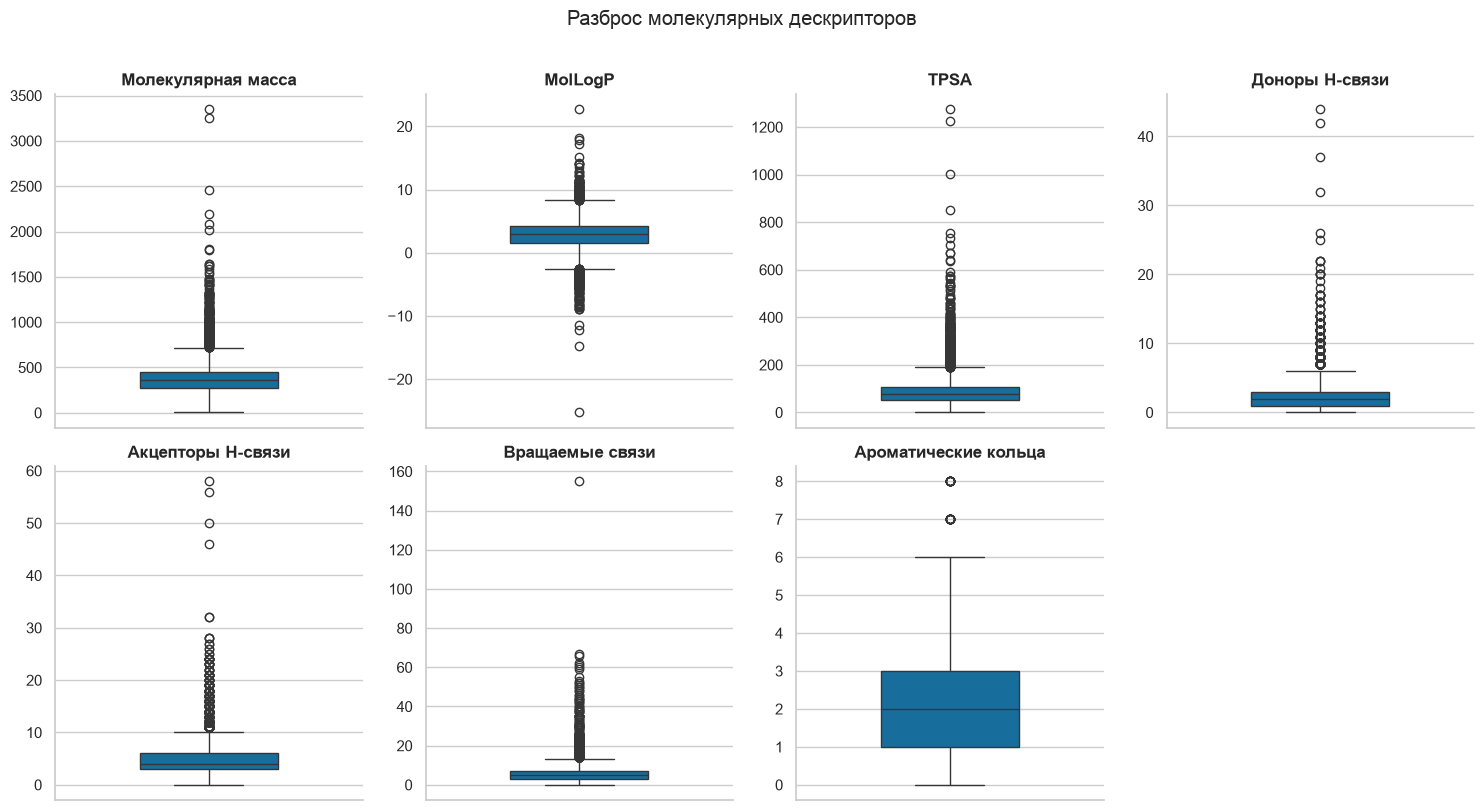

In [23]:
outlier_feature_labels = {
    "molecular_weight": "Молекулярная масса",
    "logp": "MolLogP",
    "tpsa": "TPSA",
    "h_bond_donors": "Доноры H-связи",
    "h_bond_acceptors": "Акцепторы H-связи",
    "rotatable_bonds": "Вращаемые связи",
    "aromatic_rings": "Ароматические кольца",
}

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, feature in zip(axes.flat, compound_outlier_features, strict=False):
    sns.boxplot(
        y=compounds[feature],
        color=sns.color_palette("colorblind")[0],
        width=0.45,
        ax=ax,
    )
    ax.set_title(outlier_feature_labels[feature])
    ax.set_ylabel("")
    sns.despine(ax=ax)
axes.flat[-1].set_visible(False)
fig.suptitle("Разброс молекулярных дескрипторов", y=1.01)
fig.tight_layout()
plt.show()

,id,name,molecular_weight,tpsa
11002,CHEMBL526744,NISIN,"3,353.111","1,225.600"
5590,CHEMBL2147156,POLY(AMIDOAMINE)DENDRIMER,"3,256.244","1,276.480"
11733,CHEMBL6068042,AMOGAMMADEX,"2,458.592","1,002.560"
11732,CHEMBL6068041,ALIZULATIDE VIXOCIANINE,"2,197.586",671.130
10664,CHEMBL508651,AVICIN D,"2,083.279",731.970


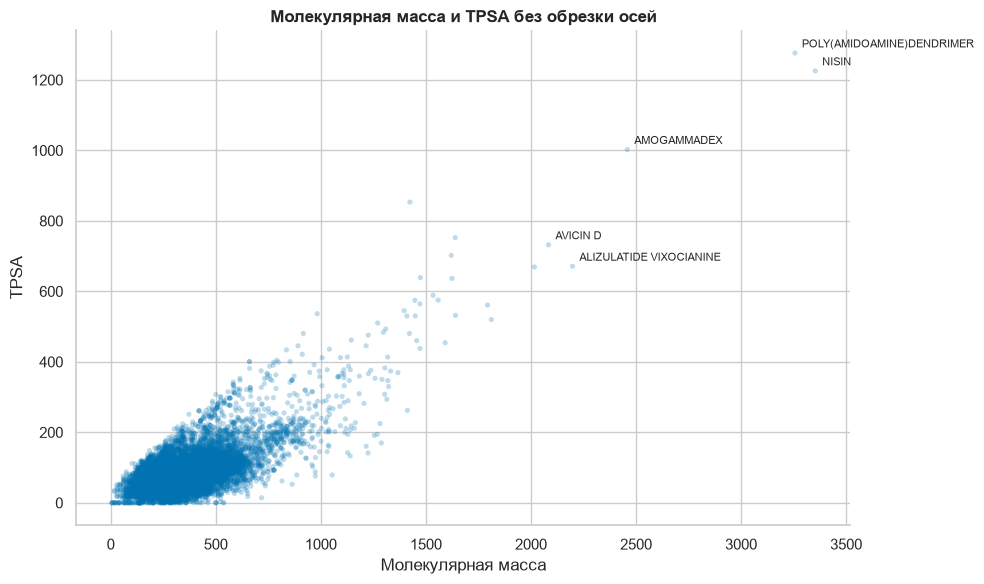

In [24]:
compound_extreme_score = compounds[["molecular_weight", "tpsa"]].rank(pct=True).sum(axis=1)
extreme_compounds = compounds.loc[
    compound_extreme_score.nlargest(5).index,
    ["id", "name", "molecular_weight", "tpsa"],
].sort_values("molecular_weight", ascending=False)
display(extreme_compounds)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(
    compounds["molecular_weight"],
    compounds["tpsa"],
    s=14, alpha=0.25, color=sns.color_palette("colorblind")[0], edgecolors="none",
)
for _, row in extreme_compounds.iterrows():
    ax.annotate(
        row["name"],
        (row["molecular_weight"], row["tpsa"]),
        xytext=(5, 4), textcoords="offset points", fontsize=8,
    )
ax.set_xlabel("Молекулярная масса")
ax.set_ylabel("TPSA")
ax.set_title("Молекулярная масса и TPSA без обрезки осей")
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

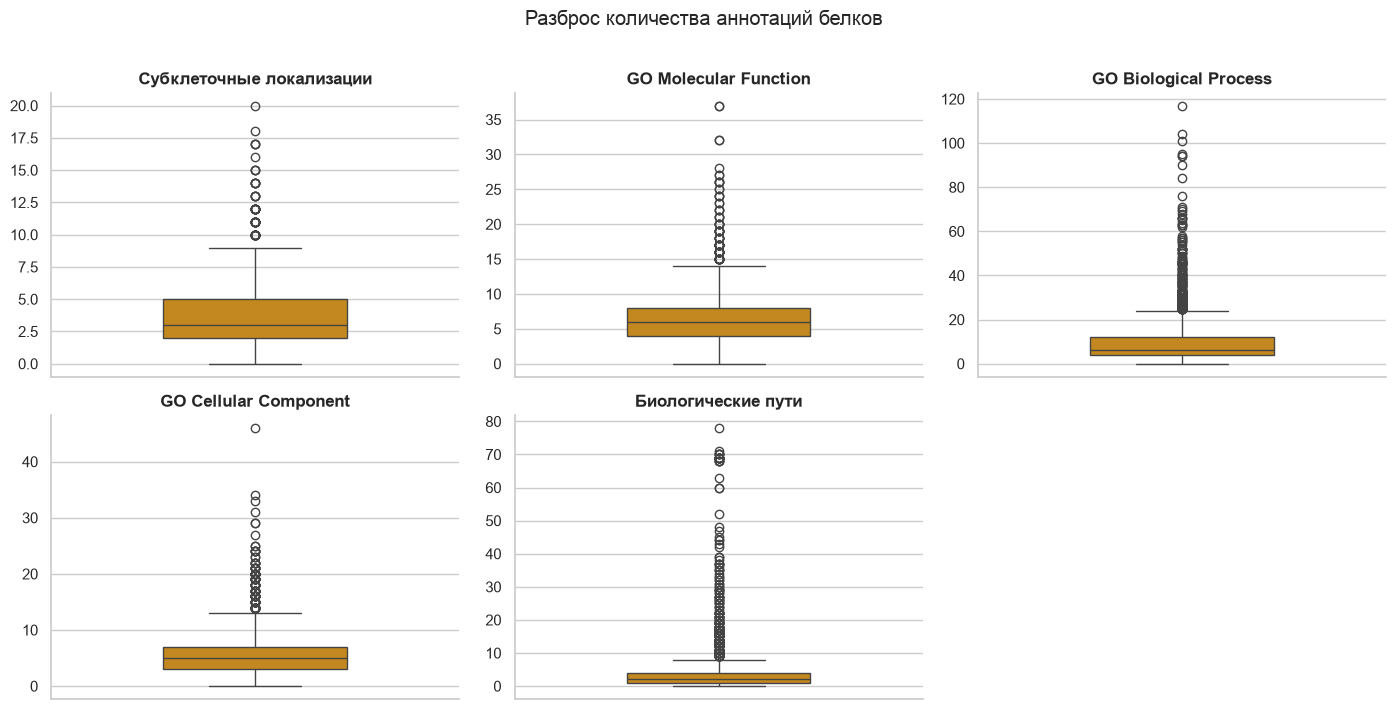

In [25]:
protein_outlier_labels = {
    "n_subcellular_locations": "Субклеточные локализации",
    "n_go_functions": "GO Molecular Function",
    "n_go_processes": "GO Biological Process",
    "n_go_components": "GO Cellular Component",
    "n_pathways": "Биологические пути",
}

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, feature in zip(axes.flat, protein_outlier_features, strict=False):
    sns.boxplot(
        y=proteins[feature],
        color=sns.color_palette("colorblind")[1],
        width=0.45,
        ax=ax,
    )
    ax.set_title(protein_outlier_labels[feature])
    ax.set_ylabel("")
    sns.despine(ax=ax)
axes.flat[-1].set_visible(False)
fig.suptitle("Разброс количества аннотаций белков", y=1.01)
fig.tight_layout()
plt.show()

## 4. Разбор связей «малая молекула — белок»

### 4.1. Общее количество объектов со связями

Сначала сравним общее количество объектов с количеством малых молекул и белков, имеющих хотя бы одну известную связь в `compound_protein`. Отсутствие записи о связи не означает доказанное отсутствие взаимодействия.

In [26]:
compound_degree = compound_protein.groupby("compound_id")["target_id"].nunique()
protein_degree = compound_protein.groupby("target_id")["compound_id"].nunique()

compounds_eda = compounds.drop(columns="parentId").assign(
    degree=compounds["id"].map(compound_degree).fillna(0).astype(int)
)
proteins_eda = proteins.assign(
    degree=proteins["id"].map(protein_degree).fillna(0).astype(int)
)
compounds_eda["has_known_link"] = compounds_eda["degree"] > 0
proteins_eda["has_known_link"] = proteins_eda["degree"] > 0

coverage = pd.DataFrame([
    {
        "Объекты": "Малые молекулы",
        "Всего": len(compounds_eda),
        "Со связями": compounds_eda["has_known_link"].sum(),
        "Без известных связей": (~compounds_eda["has_known_link"]).sum(),
        "Доля со связями, %": 100 * compounds_eda["has_known_link"].mean(),
    },
    {
        "Объекты": "Белки",
        "Всего": len(proteins_eda),
        "Со связями": proteins_eda["has_known_link"].sum(),
        "Без известных связей": (~proteins_eda["has_known_link"]).sum(),
        "Доля со связями, %": 100 * proteins_eda["has_known_link"].mean(),
    },
])

coverage_display = coverage.copy()
coverage_display["Доля со связями, %"] = coverage_display["Доля со связями, %"].round(1)
display(coverage_display)

possible_pairs = len(compounds) * len(proteins)
edge_density = len(compound_protein) / possible_pairs
print(f"Уникальных положительных связей: {len(compound_protein):,}")
print(f"Всего возможных пар: {possible_pairs:,}")
print(f"Наблюдаемая плотность: {edge_density:.6%}")

,Объекты,Всего,Со связями,Без известных связей,"Доля со связями, %"
0,Малые молекулы,12595,806,11789,6.400
1,Белки,2416,290,2126,12.000


Уникальных положительных связей: 1,202
Всего возможных пар: 30,429,520
Наблюдаемая плотность: 0.003950%


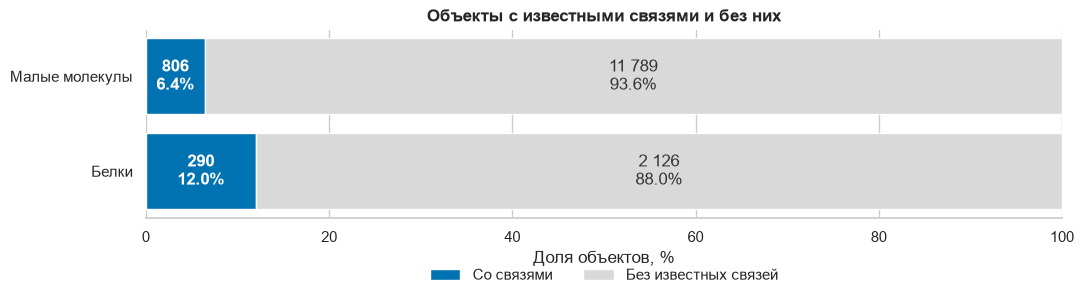

In [27]:
coverage_plot = coverage.set_index("Объекты")
linked_share = 100 * coverage_plot["Со связями"] / coverage_plot["Всего"]
unlinked_share = 100 - linked_share

fig, ax = plt.subplots(figsize=(11, 3.5))
y = np.arange(len(coverage_plot))
linked_color = sns.color_palette("colorblind")[0]
unlinked_color = "#D9D9D9"

ax.barh(y, linked_share, color=linked_color, label="Со связями")
ax.barh(
    y, unlinked_share, left=linked_share, color=unlinked_color,
    label="Без известных связей",
)

for position, object_name in enumerate(coverage_plot.index):
    linked = int(coverage_plot.loc[object_name, "Со связями"])
    unlinked = int(coverage_plot.loc[object_name, "Без известных связей"])
    linked_pct = linked_share.loc[object_name]
    unlinked_pct = unlinked_share.loc[object_name]
    linked_label = f"{linked:,}".replace(",", " ")
    unlinked_label = f"{unlinked:,}".replace(",", " ")
    ax.text(
        linked_pct / 2, position, f"{linked_label}\n{linked_pct:.1f}%",
        ha="center", va="center", color="white", fontweight="bold",
    )
    ax.text(
        linked_pct + unlinked_pct / 2, position, f"{unlinked_label}\n{unlinked_pct:.1f}%",
        ha="center", va="center", color="#333333",
    )

ax.set_yticks(y, coverage_plot.index)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Доля объектов, %")
ax.set_ylabel("")
ax.set_title("Объекты с известными связями и без них")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.42), ncol=2, frameon=False)
sns.despine(ax=ax, left=True)
fig.tight_layout()
plt.show()

### 4.2. Распределение количества связей

Количество уникальных соседей называется степенью узла. Нулевые степени уже отражены на предыдущем графике, поэтому здесь рассматриваются только объекты хотя бы с одной известной связью. Логарифмическая шкала по оси Y позволяет увидеть редкие объекты-хабы.

,Объекты,Со связями,Медиана,p90,Максимум,"Доля со степенью 1, %"
0,Малые молекулы,806,1,3,13,74.600
1,Белки,290,2,10,47,42.100


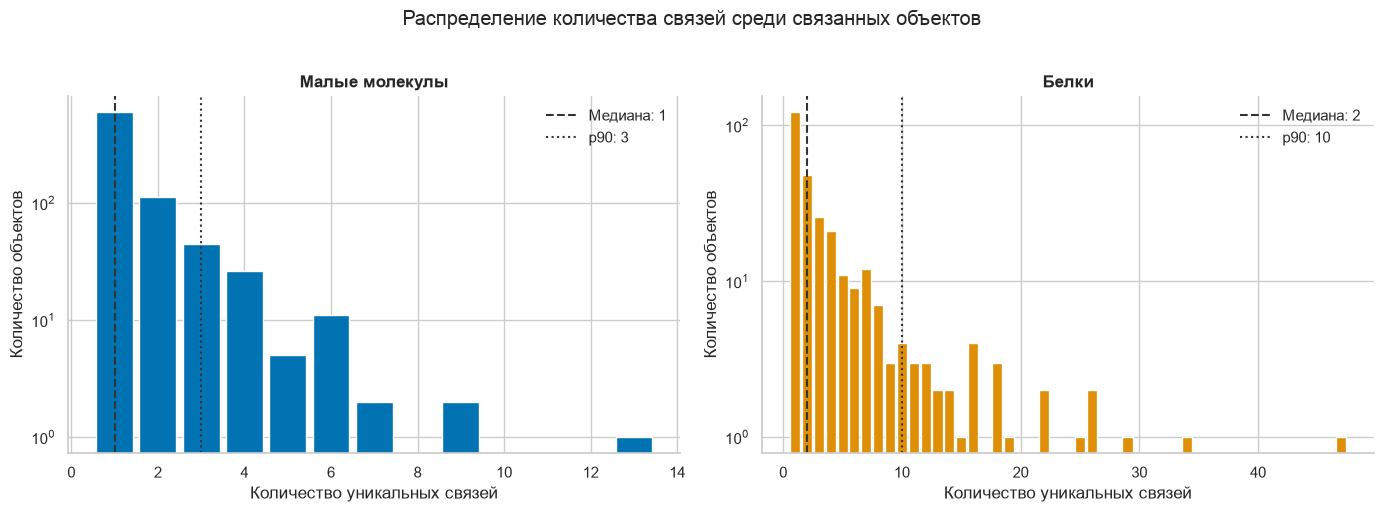

In [28]:
linked_compound_degree = compounds_eda.loc[compounds_eda["degree"] > 0, "degree"]
linked_protein_degree = proteins_eda.loc[proteins_eda["degree"] > 0, "degree"]

degree_summary = pd.DataFrame([
    {
        "Объекты": "Малые молекулы",
        "Со связями": len(linked_compound_degree),
        "Медиана": linked_compound_degree.median(),
        "p90": linked_compound_degree.quantile(0.9),
        "Максимум": linked_compound_degree.max(),
        "Доля со степенью 1, %": 100 * linked_compound_degree.eq(1).mean(),
    },
    {
        "Объекты": "Белки",
        "Со связями": len(linked_protein_degree),
        "Медиана": linked_protein_degree.median(),
        "p90": linked_protein_degree.quantile(0.9),
        "Максимум": linked_protein_degree.max(),
        "Доля со степенью 1, %": 100 * linked_protein_degree.eq(1).mean(),
    },
])
degree_summary_display = degree_summary.copy()
degree_summary_display["Медиана"] = degree_summary_display["Медиана"].round(0).astype(int)
degree_summary_display["p90"] = degree_summary_display["p90"].round(0).astype(int)
degree_summary_display["Доля со степенью 1, %"] = degree_summary_display["Доля со степенью 1, %"].round(1)
display(degree_summary_display)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, values, title, color in [
    (axes[0], linked_compound_degree, "Малые молекулы", sns.color_palette("colorblind")[0]),
    (axes[1], linked_protein_degree, "Белки", sns.color_palette("colorblind")[1]),
]:
    frequencies = values.value_counts().sort_index()
    median = values.median()
    percentile_90 = values.quantile(0.9)

    ax.bar(frequencies.index, frequencies.values, color=color, width=0.85)
    ax.axvline(median, color="#333333", linestyle="--", linewidth=1.5, label=f"Медиана: {median:.0f}")
    ax.axvline(
        percentile_90, color="#333333", linestyle=":", linewidth=1.5,
        label=f"p90: {percentile_90:.0f}",
    )
    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_xlabel("Количество уникальных связей")
    ax.set_ylabel("Количество объектов")
    ax.legend(frameon=False)
    sns.despine(ax=ax)

fig.suptitle("Распределение количества связей среди связанных объектов", y=1.02)
fig.tight_layout()
plt.show()

### 4.3. Виды связей между малыми молекулами и белками

Поле `actionType` описывает направленность фармакологического действия для пары «молекула — белок». `mechanismOfAction` содержит более подробную текстовую формулировку механизма.

Поля хранятся в виде списков, поскольку при подготовке данных несколько исходных записей могли быть объединены в одну пару. Сначала проверим фактическую кардинальность этих списков и тип мишени.

In [29]:
action_count = compound_protein["actionType"].str.len()
mechanism_count = compound_protein["mechanismOfAction"].str.len()

link_structure = pd.DataFrame([
    {"Проверка": "Пустой actionType", "Количество пар": action_count.eq(0).sum()},
    {"Проверка": "Более одного actionType", "Количество пар": action_count.gt(1).sum()},
    {"Проверка": "Пустой mechanismOfAction", "Количество пар": mechanism_count.eq(0).sum()},
    {"Проверка": "Более одного mechanismOfAction", "Количество пар": mechanism_count.gt(1).sum()},
    {
        "Проверка": "Более одной исходной записи",
        "Количество пар": compound_protein["n_source_links"].gt(1).sum(),
    },
    {
        "Проверка": "Мишень не single protein",
        "Количество пар": compound_protein["targetType"].ne("single protein").sum(),
    },
])
link_structure["Доля пар, %"] = (
    100 * link_structure["Количество пар"] / len(compound_protein)
).round(1)
display(link_structure)

print(f"Уникальных значений targetType: {compound_protein['targetType'].nunique()}")
print(f"Всего исходных записей после агрегации: {compound_protein['n_source_links'].sum():,}")

,Проверка,Количество пар,"Доля пар, %"
0,Пустой actionType,0,0.000
1,Более одного actionType,0,0.000
2,Пустой mechanismOfAction,0,0.000
3,Более одного mechanismOfAction,1,0.100
4,Более одной исходной записи,239,19.900
5,Мишень не single protein,0,0.000


Уникальных значений targetType: 1
Всего исходных записей после агрегации: 1,467


In [30]:
action_links = (
    compound_protein
    .explode("actionType")
    .dropna(subset=["actionType"])
    .rename(columns={"actionType": "action_type"})
)

action_summary = (
    action_links
    .groupby("action_type")
    .agg(
        n_links=("target_id", "size"),
        n_compounds=("compound_id", "nunique"),
        n_proteins=("target_id", "nunique"),
    )
    .assign(share_pct=lambda frame: 100 * frame["n_links"] / frame["n_links"].sum())
    .sort_values("n_links", ascending=False)
)

action_summary.rename(columns={
    "n_links": "Связей",
    "n_compounds": "Молекул",
    "n_proteins": "Белков",
    "share_pct": "Доля связей, %",
}).round({"Доля связей, %": 2})

,Связей,Молекул,Белков,"Доля связей, %"
action_type,,,,
INHIBITOR,1175,781,280,97.750
ACTIVATOR,14,13,8,1.160
STABILISER,4,4,4,0.330
NEGATIVE ALLOSTERIC MODULATOR,3,2,3,0.250
POSITIVE ALLOSTERIC MODULATOR,2,2,2,0.170
AGONIST,1,1,1,0.080
ANTAGONIST,1,1,1,0.080
MODULATOR,1,1,1,0.080
OTHER,1,1,1,0.080


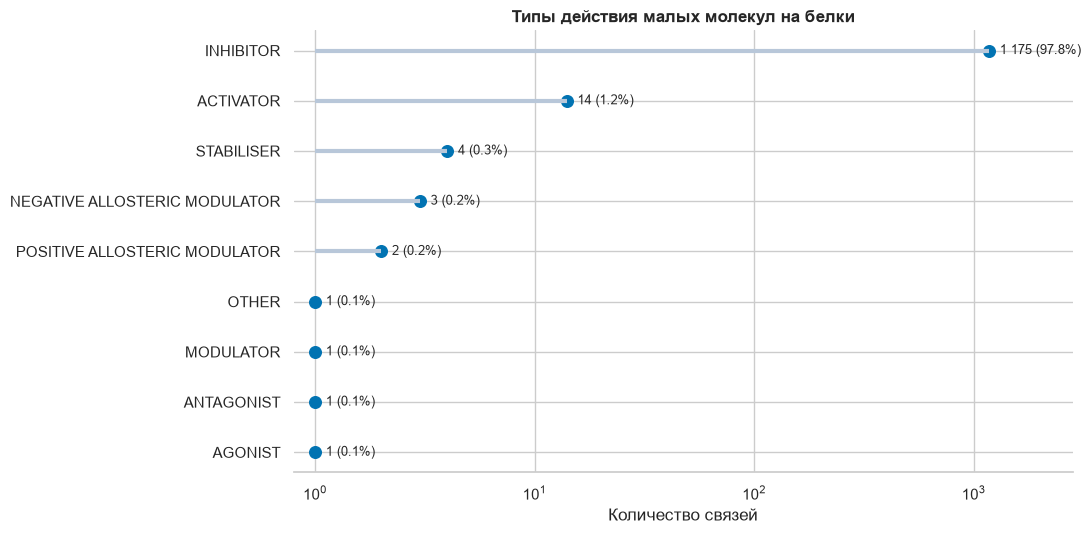

In [31]:
plot_data = action_summary.sort_values("n_links")
positions = np.arange(len(plot_data))
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.hlines(positions, xmin=1, xmax=plot_data["n_links"], color="#B8C7D9", linewidth=3)
ax.scatter(plot_data["n_links"], positions, color=sns.color_palette("colorblind")[0], s=70)

for position, (_, row) in zip(positions, plot_data.iterrows(), strict=True):
    ax.text(
        row["n_links"] * 1.12, position,
        f"{int(row['n_links']):,} ({row['share_pct']:.1f}%)".replace(",", " ") ,
        va="center", fontsize=9,
    )

ax.set_xscale("log")
ax.set_xlim(0.8, plot_data["n_links"].max() * 2.4)
ax.set_yticks(positions, plot_data.index)
ax.set_xlabel("Количество связей")
ax.set_ylabel("")
ax.set_title("Типы действия малых молекул на белки")
sns.despine(ax=ax, left=True)
fig.tight_layout()
plt.show()

INHIBITOR составляет 97.8% всех связей. На остальные 8 типов приходится только 27 связей.

#### Редкие, неингибирующие типы

Из-за малого числа наблюдений редкие типы полезнее рассмотреть на уровне отдельных пар. Таблица ниже также помогает проверить, что короткий `actionType` согласуется с текстовым механизмом.

In [32]:
rare_action_links = (
    action_links.loc[action_links["action_type"] != "INHIBITOR"]
    .merge(
        compounds[["id", "name", "maximumClinicalStage"]],
        left_on="compound_id", right_on="id", how="left",
    )
    .merge(
        proteins[["id", "approvedSymbol", "enzyme_subfamilies"]],
        left_on="target_id", right_on="id", how="left",
        suffixes=("_compound", "_protein"),
    )
)
rare_action_links["mechanism"] = rare_action_links["mechanismOfAction"].str.join("; ")
rare_action_links["enzyme_class"] = rare_action_links["enzyme_subfamilies"].apply(
    lambda values: "; ".join(values) if values else "Нет L2-аннотации"
)

rare_action_display = (
    rare_action_links[[
        "name", "approvedSymbol", "action_type", "mechanism",
        "enzyme_class", "maximumClinicalStage",
    ]]
    .sort_values(["action_type", "name"])
    .rename(columns={
        "name": "Малая молекула",
        "approvedSymbol": "Белок",
        "action_type": "Тип действия",
        "mechanism": "Механизм",
        "enzyme_class": "Класс фермента",
        "maximumClinicalStage": "Клиническая стадия",
    })
)
display(rare_action_display)

,Малая молекула,Белок,Тип действия,Механизм,Класс фермента,Клиническая стадия
15,AZD-1656,GCK,ACTIVATOR,Hexokinase type IV activator,Нет L2-аннотации,PHASE_2
19,DORZAGLIATIN,GCK,ACTIVATOR,Hexokinase type IV activator,Нет L2-аннотации,APPROVAL
25,ETAVOPIVAT,PKLR,ACTIVATOR,Pyruvate kinase isozymes R/L activator,Нет L2-аннотации,PHASE_3
7,ISTAROXIME,ATP2A2,ACTIVATOR,Sarcoplasmic/endoplasmic reticulum calcium ATP...,Hydrolase,PHASE_2_3
18,LY-2608204,GCK,ACTIVATOR,Hexokinase type IV activator,Нет L2-аннотации,PHASE_2
20,MITAPIVAT,PKLR,ACTIVATOR,Pyruvate kinase isozymes R/L activator,Нет L2-аннотации,APPROVAL
16,MK-0941 FREE BASE,GCK,ACTIVATOR,Hexokinase type IV activator,Нет L2-аннотации,UNKNOWN
11,NERIGLIATIN,GCK,ACTIVATOR,Hexokinase type IV activator,Нет L2-аннотации,PHASE_2
12,PF-04991532,GCK,ACTIVATOR,Hexokinase type IV activator,Нет L2-аннотации,PHASE_2
4,PRALIDOXIME,ACHE,ACTIVATOR,Acetylcholinesterase activator,Hydrolase,PHASE_2


#### Сколько типов действия связано с одним объектом

Тип действия относится к паре, а не к молекуле или белку по отдельности. Поэтому проверим, встречаются ли у одного объекта разные типы в разных связях.

In [33]:
compound_action_diversity = action_links.groupby("compound_id")["action_type"].nunique()
protein_action_diversity = action_links.groupby("target_id")["action_type"].nunique()

entity_action_summary = pd.DataFrame([
    {
        "Объекты": "Малые молекулы со связями",
        "Всего": len(compound_action_diversity),
        "С одним типом действия": compound_action_diversity.eq(1).sum(),
        "С несколькими типами действия": compound_action_diversity.gt(1).sum(),
    },
    {
        "Объекты": "Белки со связями",
        "Всего": len(protein_action_diversity),
        "С одним типом действия": protein_action_diversity.eq(1).sum(),
        "С несколькими типами действия": protein_action_diversity.gt(1).sum(),
    },
])
display(entity_action_summary)

protein_action_sets = (
    action_links
    .groupby("target_id")
    .agg(
        action_types=("action_type", lambda values: sorted(set(values))),
        n_compounds=("compound_id", "nunique"),
    )
)
multi_action_proteins = (
    protein_action_sets.loc[protein_action_sets["action_types"].str.len() > 1]
    .merge(proteins[["id", "approvedSymbol"]], left_index=True, right_on="id")
    .assign(action_types=lambda frame: frame["action_types"].str.join(" / "))
    .sort_values("n_compounds", ascending=False)
)
display(
    multi_action_proteins[["approvedSymbol", "action_types", "n_compounds"]]
    .rename(columns={
        "approvedSymbol": "Белок",
        "action_types": "Наблюдаемые типы действия",
        "n_compounds": "Связанных молекул",
    })
)

,Объекты,Всего,С одним типом действия,С несколькими типами действия
0,Малые молекулы со связями,806,806,0
1,Белки со связями,290,279,11


,Белок,Наблюдаемые типы действия,Связанных молекул
1403,EGFR,INHIBITOR / NEGATIVE ALLOSTERIC MODULATOR,47
593,MET,AGONIST / INHIBITOR,26
1315,ERBB2,INHIBITOR / NEGATIVE ALLOSTERIC MODULATOR,22
349,ACHE,ACTIVATOR / INHIBITOR,19
2269,TOP1,INHIBITOR / STABILISER,16
2007,TYMS,ANTAGONIST / INHIBITOR,9
571,TYK2,INHIBITOR / NEGATIVE ALLOSTERIC MODULATOR,7
2171,MAOA,ACTIVATOR / INHIBITOR,4
2386,LYN,INHIBITOR / POSITIVE ALLOSTERIC MODULATOR,4
547,GSR,INHIBITOR / OTHER,2


#### Текстовые механизмы действия

`mechanismOfAction` существенно детальнее `actionType`: формулировка обычно объединяет конкретную мишень и тип действия. Поэтому это поле анализируется как текстовая аннотация, а не как ещё одна независимая система классов.

,Показатель,Значение
0,Уникальные текстовые механизмы,303
1,Упоминания механизмов,1 203
2,Пары с несколькими формулировками,1
3,Доля 10 наиболее частых механизмов,21.9%


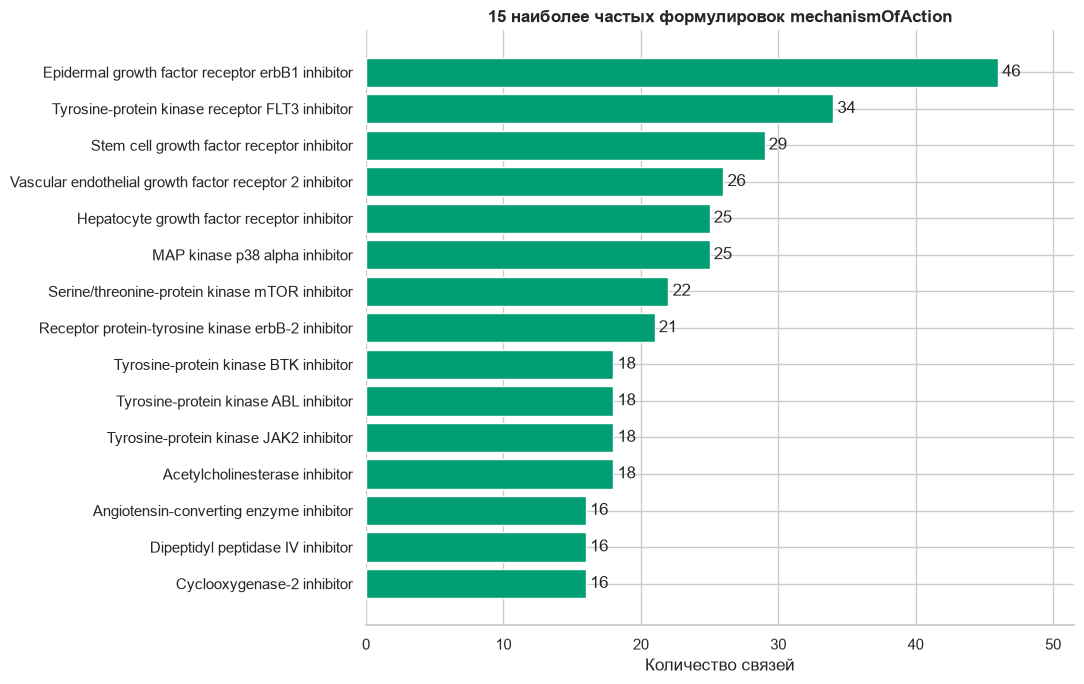

**Пары с несколькими текстовыми формулировками механизма:**

,compound_id,target_id,actionType,mechanismOfAction,n_source_links
715,CHEMBL3787344,ENSG00000146648,[INHIBITOR],[Epidermal growth factor receptor erbB1 inhibi...,2


In [34]:
mechanism_links = (
    compound_protein[["compound_id", "target_id", "actionType", "mechanismOfAction"]]
    .explode("mechanismOfAction")
    .dropna(subset=["mechanismOfAction"])
)
mechanism_frequency = mechanism_links["mechanismOfAction"].value_counts()
top_10_share = 100 * mechanism_frequency.head(10).sum() / len(mechanism_links)

mechanism_summary = pd.DataFrame({
    "Показатель": [
        "Уникальные текстовые механизмы",
        "Упоминания механизмов",
        "Пары с несколькими формулировками",
        "Доля 10 наиболее частых механизмов",
    ],
    "Значение": [
        f"{mechanism_frequency.size:,}".replace(",", " ") ,
        f"{len(mechanism_links):,}".replace(",", " ") ,
        f"{mechanism_count.gt(1).sum():,}".replace(",", " ") ,
        f"{top_10_share:.1f}%",
    ],
})
display(mechanism_summary)

top_mechanisms = mechanism_frequency.head(15).sort_values()
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(top_mechanisms.index, top_mechanisms.values, color=sns.color_palette("colorblind")[2])
ax.bar_label(ax.containers[0], padding=3)
ax.set_xlabel("Количество связей")
ax.set_ylabel("")
ax.set_title("15 наиболее частых формулировок mechanismOfAction")
ax.set_xlim(0, top_mechanisms.max() * 1.12)
sns.despine(ax=ax, left=True)
fig.tight_layout()
plt.show()

multiple_mechanisms = compound_protein.loc[
    mechanism_count.gt(1),
    ["compound_id", "target_id", "actionType", "mechanismOfAction", "n_source_links"],
]
if not multiple_mechanisms.empty:
    display(Markdown("**Пары с несколькими текстовыми формулировками механизма:**"))
    display(multiple_mechanisms)

#### Типы действия и классы ферментов

Сопоставим тип действия с подсемейством фермента второго уровня. Цвет показан в логарифмическом масштабе, а подписи содержат исходные количества: иначе преобладание ингибиторов скрыло бы редкие сочетания. Пустая L2-аннотация означает отсутствие более детального класса в Open Targets, а не отдельный биологический класс.

,Связей,"Доля INHIBITOR, %"
enzyme_subfamilies,,
Kinase,698,99.300
Oxidoreductase,125,96.000
Protease,111,100.000
Transferase,87,98.900
Hydrolase,47,91.500
Isomerase,31,96.800
Cytochrome P450,25,100.000
Lyase,24,100.000
Phosphodiesterase,23,100.000


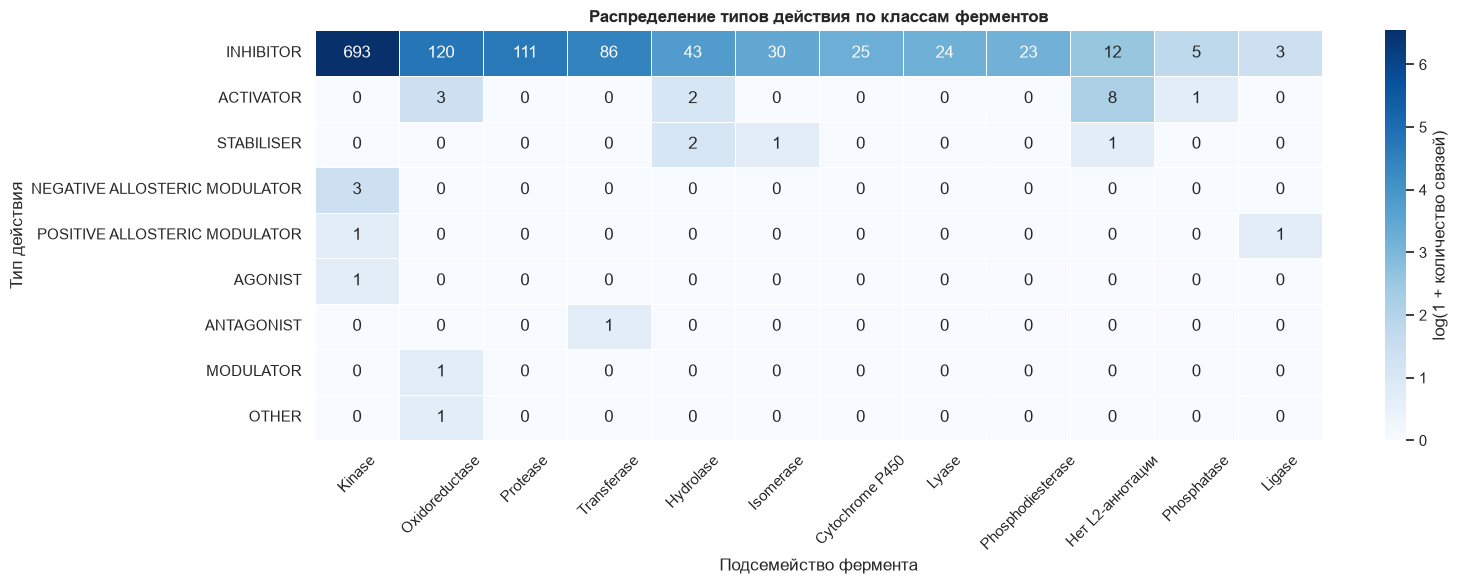

In [35]:
protein_classes = proteins[["id", "enzyme_subfamilies"]].copy()
protein_classes["enzyme_subfamilies"] = protein_classes["enzyme_subfamilies"].apply(
    lambda values: values if values else ["Нет L2-аннотации"]
)

action_with_class = (
    action_links[["target_id", "action_type"]]
    .merge(protein_classes, left_on="target_id", right_on="id", how="left")
    .explode("enzyme_subfamilies")
)
action_by_class = pd.crosstab(
    action_with_class["action_type"], action_with_class["enzyme_subfamilies"]
)
action_by_class = action_by_class.reindex(
    index=action_summary.index,
    columns=action_by_class.sum().sort_values(ascending=False).index,
)

class_summary = pd.DataFrame({
    "Связей": action_by_class.sum(),
    "Доля INHIBITOR, %": (
        100 * action_by_class.loc["INHIBITOR"] / action_by_class.sum()
    ).round(1),
}).sort_values("Связей", ascending=False)
display(class_summary)

fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(
    np.log1p(action_by_class),
    annot=action_by_class, fmt="d", cmap="Blues", linewidths=0.5,
    cbar_kws={"label": "log(1 + количество связей)"},
    ax=ax,
)
ax.set_xlabel("Подсемейство фермента")
ax.set_ylabel("Тип действия")
ax.set_title("Распределение типов действия по классам ферментов")
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()

### 4.4. Выводы и расширение набора связей

В текущем релизе представлено 9 категорий `actionType`, однако датасет почти полностью состоит из ингибирования: 1 175 из 1 202 связей (97,8%). Каждая пара имеет ровно один `actionType`; только одна пара содержит две текстовые формулировки механизма. Среди 806 связанных молекул не встречается молекул с разными типами действия, тогда как 11 белков связаны с молекулами разных типов действия. `mechanismOfAction` содержит 303 уникальные, преимущественно мишень-специфичные формулировки.

Для моделирования из этого следуют три ограничения:

- неизвестная пара не является подтверждённой отрицательной связью; это лишь отсутствие записи в текущем источнике;
- редкие `actionType` нельзя надёжно оценивать обычным случайным разбиением без стратификации и отдельного контроля малых классов;
- `actionType` описывает направленность механизма, но не силу взаимодействия, условия эксперимента или качество доказательства.

При подключении внешнего источника, например ChemDB или ChEMBL, измерения биоактивности следует хранить отдельно от `actionType`. Полезная схема длинного формата может включать `compound_id`, `target_id`, `relation_type`, `activity_type` (например, IC50, Ki, Kd или EC50), знак сравнения, значение, единицы, нормализованную активность, `assay_id`, тип/организм теста, уровень достоверности и источник. Тогда несколько экспериментов для одной пары не будут ошибочно превращены в несколько независимых связей. Для объединения также потребуется явное сопоставление химических идентификаторов и мишеней с Ensembl и сохранение происхождения каждой записи.

## 5. Совместные распределения характеристик объектов

Одномерные распределения не показывают, какие признаки изменяются совместно и отличаются ли они между группами объектов. Ниже рассматриваются три вида связей между характеристиками:

1. непрерывная — непрерывная: ранговые корреляции и диаграммы рассеивания;
2. категориальная — непрерывная: violinplot и boxplot;
3. характеристики объекта — наличие и количество известных связей.

### 5.1. Совместные распределения характеристик малых молекул

Для счётных и непрерывных молекулярных дескрипторов используем корреляцию Спирмена. Она оценивает монотонную связь, не требует нормального распределения и устойчивее корреляции Пирсона к асимметрии и выбросам. Высокая корреляция не означает, что признаки взаимозаменяемы, но указывает на возможную избыточность информации.

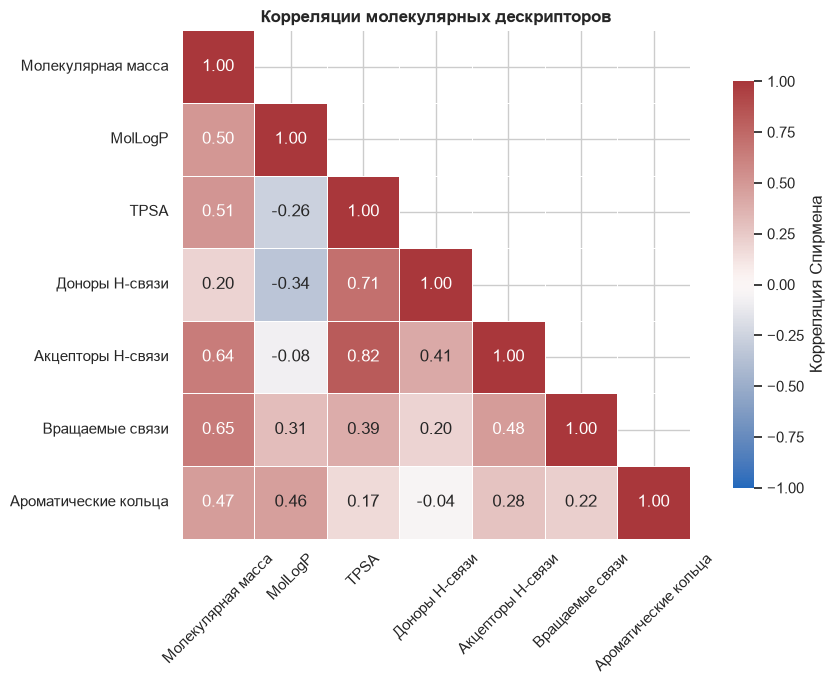

In [36]:
compound_features = [
    "molecular_weight",
    "logp",
    "tpsa",
    "h_bond_donors",
    "h_bond_acceptors",
    "rotatable_bonds",
    "aromatic_rings",
]
compound_feature_labels = {
    "molecular_weight": "Молекулярная масса",
    "logp": "MolLogP",
    "tpsa": "TPSA",
    "h_bond_donors": "Доноры H-связи",
    "h_bond_acceptors": "Акцепторы H-связи",
    "rotatable_bonds": "Вращаемые связи",
    "aromatic_rings": "Ароматические кольца",
}

compound_corr = compounds_eda[compound_features].corr(method="spearman")
compound_corr = compound_corr.rename(
    index=compound_feature_labels, columns=compound_feature_labels
)
upper_triangle = np.triu(np.ones_like(compound_corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    compound_corr, mask=upper_triangle, annot=True, fmt=".2f",
    cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
    linewidths=0.5, cbar_kws={"label": "Корреляция Спирмена", "shrink": 0.8},
    ax=ax,
)
ax.set_title("Корреляции молекулярных дескрипторов")
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()

#### Диаграммы рассеивания

Корреляция сводит совместное распределение к одному числу. Scatterplot дополнительно показывает форму зависимости, неоднородность разброса и области, в которых сосредоточены молекулы с известными связями. Серым показаны молекулы без записи в `compound_protein`, синим — молекулы хотя бы с одной известной связью. Синий класс рисуется поверх серого, поскольку он существенно меньше.

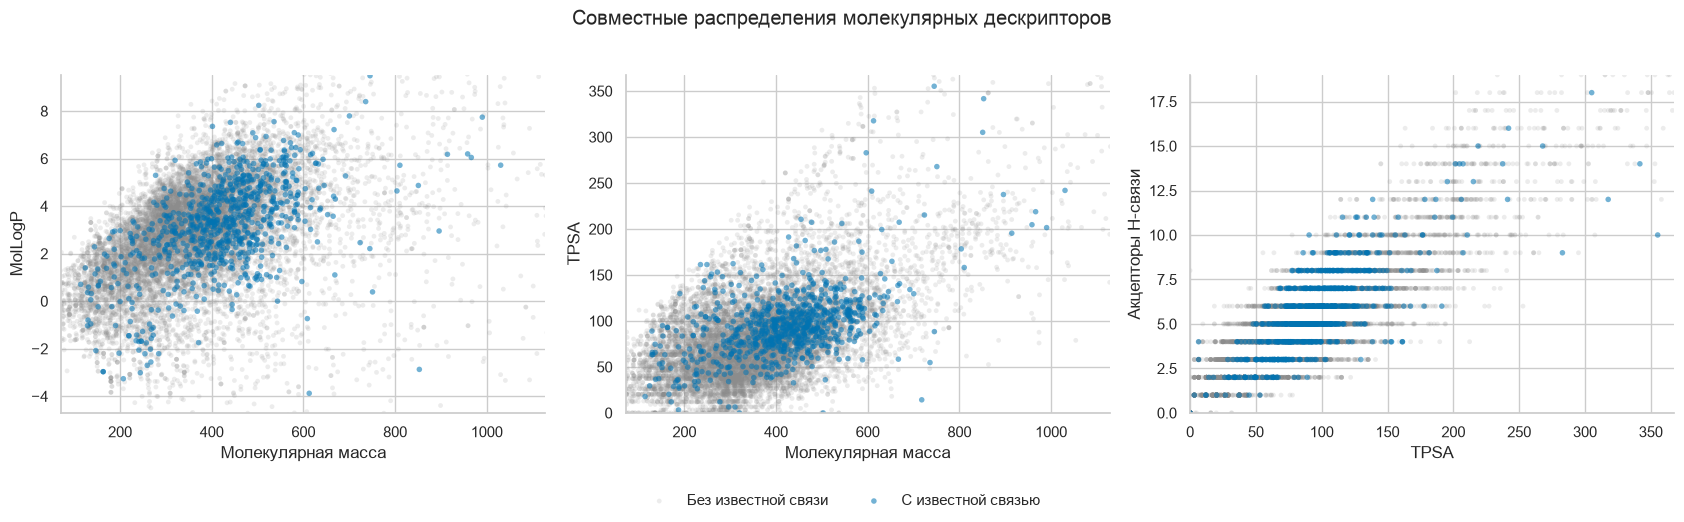

In [37]:
def set_central_limits(ax, data, x, y, lower=0.005, upper=0.995):
    ax.set_xlim(data[x].quantile(lower), data[x].quantile(upper))
    ax.set_ylim(data[y].quantile(lower), data[y].quantile(upper))


scatter_pairs = [
    ("molecular_weight", "logp"),
    ("molecular_weight", "tpsa"),
    ("tpsa", "h_bond_acceptors"),
]
unlinked_compounds = compounds_eda.loc[~compounds_eda["has_known_link"]]
linked_compounds = compounds_eda.loc[compounds_eda["has_known_link"]]
linked_color = sns.color_palette("colorblind")[0]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (x_feature, y_feature) in zip(axes, scatter_pairs, strict=True):
    ax.scatter(
        unlinked_compounds[x_feature], unlinked_compounds[y_feature],
        s=12, alpha=0.16, color="#8C8C8C", edgecolors="none",
        rasterized=True, label="Без известной связи",
    )
    ax.scatter(
        linked_compounds[x_feature], linked_compounds[y_feature],
        s=16, alpha=0.55, color=linked_color, edgecolors="none",
        rasterized=True, label="С известной связью",
    )
    set_central_limits(ax, compounds_eda, x_feature, y_feature)
    ax.set_xlabel(compound_feature_labels[x_feature])
    ax.set_ylabel(compound_feature_labels[y_feature])
    sns.despine(ax=ax)

handles, labels = axes[0].get_legend_handles_labels()
for ax in axes:
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Совместные распределения молекулярных дескрипторов", y=1.02)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

#### Молекулярные характеристики в зависимости от клинической стадии

`maximumClinicalStage` — категориальный признак с несколькими значениями. Violinplot показывает не только медиану и квартили, но и форму распределения внутри каждой стадии. Ширина каждой скрипки нормирована независимо, поэтому количество объектов вынесено в подпись категории. Стадии упорядочены для чтения, но расстояние между соседними категориями не является числовой шкалой.

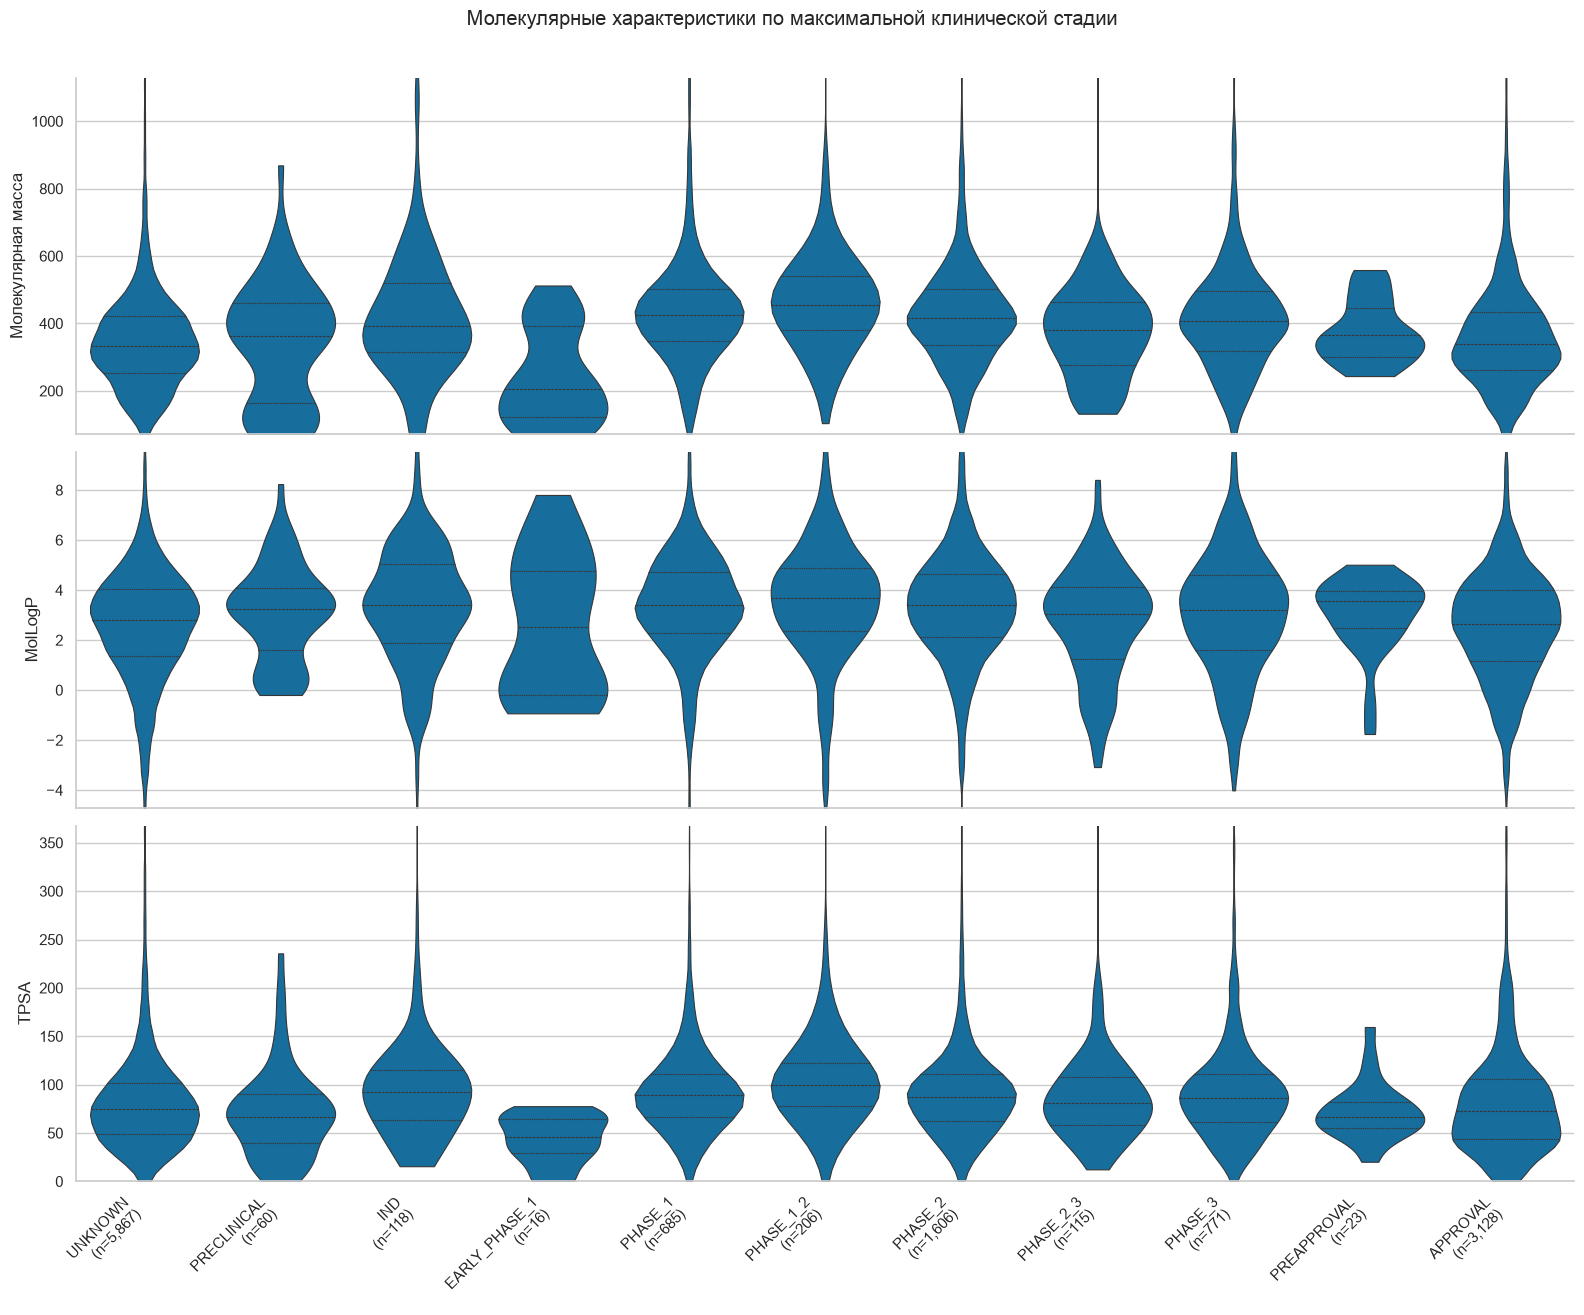

In [38]:
stage_order = [
    "UNKNOWN",
    "PRECLINICAL",
    "IND",
    "EARLY_PHASE_1",
    "PHASE_1",
    "PHASE_1_2",
    "PHASE_2",
    "PHASE_2_3",
    "PHASE_3",
    "PREAPPROVAL",
    "APPROVAL",
]
stage_order = [
    stage for stage in stage_order
    if stage in compounds_eda["maximumClinicalStage"].unique()
]
stage_sizes = compounds_eda["maximumClinicalStage"].value_counts()
stage_tick_labels = [f"{stage}\n(n={stage_sizes[stage]:,})" for stage in stage_order]
stage_features = ["molecular_weight", "logp", "tpsa"]

fig, axes = plt.subplots(3, 1, figsize=(16, 13), sharex=True)
for ax, feature in zip(axes, stage_features, strict=True):
    sns.violinplot(
        data=compounds_eda, x="maximumClinicalStage", y=feature,
        order=stage_order, inner="quartile", cut=0, density_norm="width",
        bw_adjust=0.8, linewidth=0.8, color=sns.color_palette("colorblind")[0],
        ax=ax,
    )
    ax.set_ylim(
        compounds_eda[feature].quantile(0.005),
        compounds_eda[feature].quantile(0.995),
    )
    ax.set_ylabel(compound_feature_labels[feature])
    ax.set_xlabel("")
    sns.despine(ax=ax)

axes[-1].set_xticks(range(len(stage_order)), stage_tick_labels, rotation=45, ha="right")
fig.suptitle("Молекулярные характеристики по максимальной клинической стадии", y=1.01)
fig.tight_layout()
plt.show()

#### Характеристики молекул и наличие известной связи

Сравнение с `has_known_link` проверяет, одинаково ли представлены разные области химического пространства в таблице связей. Это описательный анализ покрытия: отсутствие известной связи не является отрицательным классом, а наблюдаемые различия могут отражать состав источника и клинические стадии молекул.

,Объектов,Медиана массы,Медиана MolLogP,Медиана TPSA
link_status,,,,
Без известной связи,11789,354.410,2.920,76.150
С известной связью,806,425.500,3.290,93.010


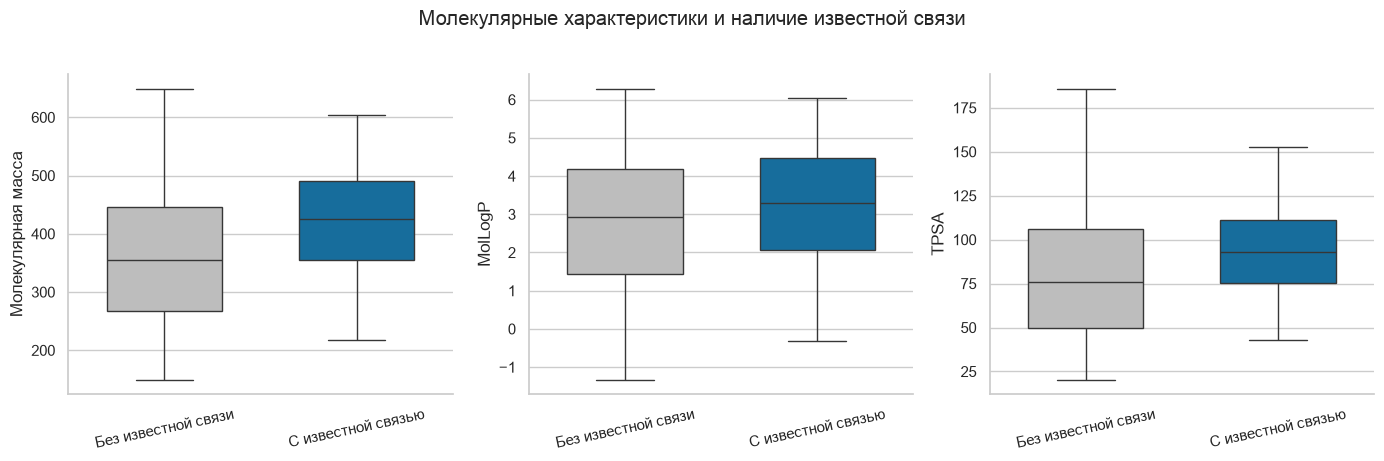

In [39]:
compound_link_comparison = (
    compounds_eda
    .assign(
        link_status=np.where(
            compounds_eda["has_known_link"],
            "С известной связью",
            "Без известной связи",
        )
    )
)
link_status_order = ["Без известной связи", "С известной связью"]

compound_link_summary = (
    compound_link_comparison
    .groupby("link_status", observed=True)
    .agg(
        objects=("id", "size"),
        median_mw=("molecular_weight", "median"),
        median_logp=("logp", "median"),
        median_tpsa=("tpsa", "median"),
    )
    .reindex(link_status_order)
    .rename(columns={
        "objects": "Объектов",
        "median_mw": "Медиана массы",
        "median_logp": "Медиана MolLogP",
        "median_tpsa": "Медиана TPSA",
    })
)
display(compound_link_summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, feature in zip(axes, stage_features, strict=True):
    sns.boxplot(
        data=compound_link_comparison, x="link_status", y=feature,
        order=link_status_order, hue="link_status", palette=["#BDBDBD", linked_color],
        legend=False, showfliers=False, whis=(5, 95), width=0.6, ax=ax,
    )
    ax.set_xlabel("")
    ax.set_ylabel(compound_feature_labels[feature])
    ax.tick_params(axis="x", rotation=12)
    sns.despine(ax=ax)

fig.suptitle("Молекулярные характеристики и наличие известной связи", y=1.02)
fig.tight_layout()
plt.show()

### 5.2. Совместные распределения характеристик белков

Числовые признаки белков в основном описывают объём доступной аннотации. Их совместное рассмотрение позволяет выявить общий эффект изученности белка и проверить, связан ли он с количеством известных малых молекул. `degree` включён в матрицу как число уникальных связанных молекул.

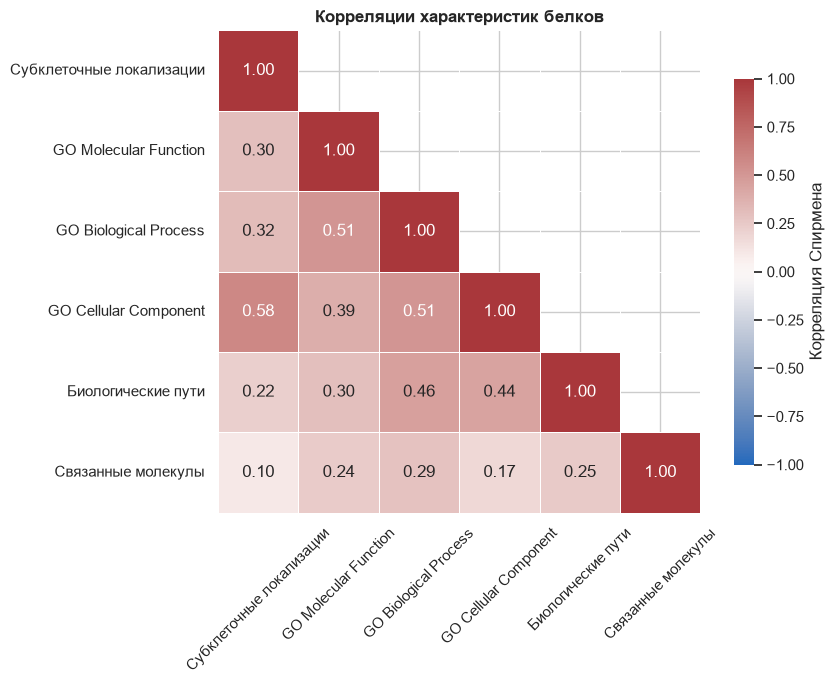

In [40]:
protein_features = [
    "n_subcellular_locations",
    "n_go_functions",
    "n_go_processes",
    "n_go_components",
    "n_pathways",
    "degree",
]
protein_feature_labels = {
    "n_subcellular_locations": "Субклеточные локализации",
    "n_go_functions": "GO Molecular Function",
    "n_go_processes": "GO Biological Process",
    "n_go_components": "GO Cellular Component",
    "n_pathways": "Биологические пути",
    "degree": "Связанные молекулы",
}

protein_corr = proteins_eda[protein_features].corr(method="spearman")
protein_corr = protein_corr.rename(
    index=protein_feature_labels, columns=protein_feature_labels
)
upper_triangle = np.triu(np.ones_like(protein_corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    protein_corr, mask=upper_triangle, annot=True, fmt=".2f",
    cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
    linewidths=0.5, cbar_kws={"label": "Корреляция Спирмена", "shrink": 0.8},
    ax=ax,
)
ax.set_title("Корреляции характеристик белков")
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()

#### Аннотации белков и наличие известных связей

На scatterplot показано совместное число аннотаций биологических процессов и путей. Boxplot сравнивает эти характеристики между белками с известными связями и без них; усы соответствуют 5-му и 95-му перцентилям группы. Различия следует интерпретировать прежде всего как возможное смещение в сторону лучше изученных белков.

,Объектов,Медиана GO процессов,Медиана GO функций,Медиана GO компонентов,Медиана путей
link_status,,,,,
Без известной связи,2126,6.000,6.000,4.000,2.000
С известной связью,290,14.000,8.000,7.000,4.000


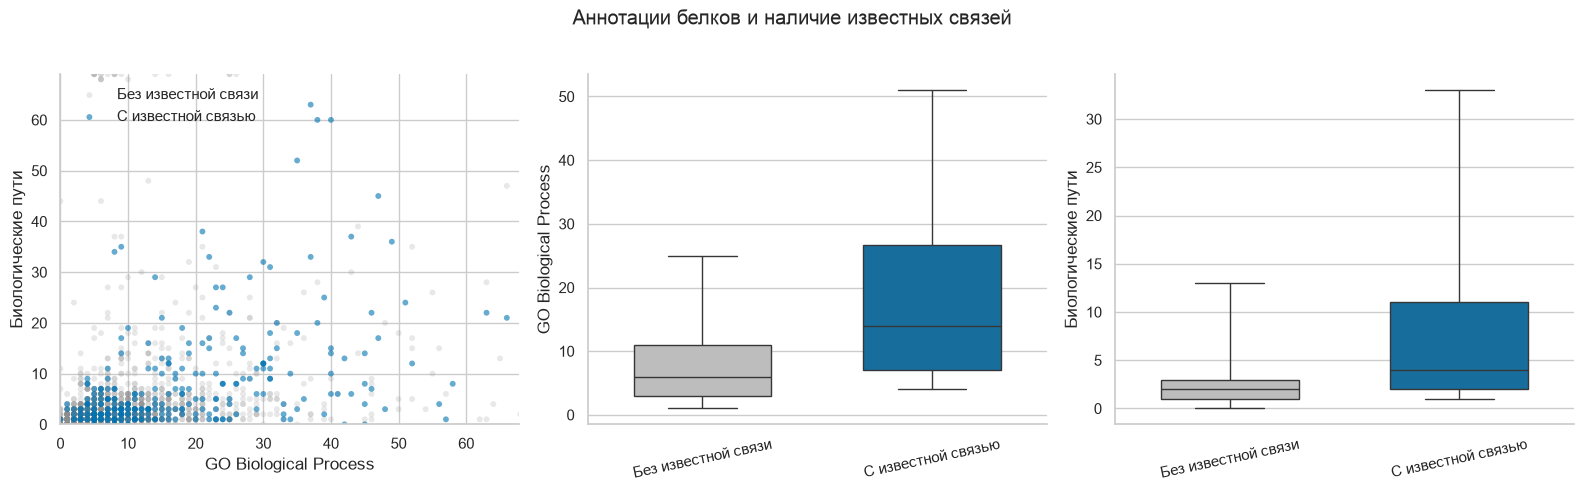

In [41]:
protein_link_comparison = proteins_eda.assign(
    link_status=np.where(
        proteins_eda["has_known_link"],
        "С известной связью",
        "Без известной связи",
    )
)
protein_link_summary = (
    protein_link_comparison
    .groupby("link_status", observed=True)
    .agg(
        objects=("id", "size"),
        median_go_processes=("n_go_processes", "median"),
        median_go_functions=("n_go_functions", "median"),
        median_go_components=("n_go_components", "median"),
        median_pathways=("n_pathways", "median"),
    )
    .reindex(link_status_order)
    .rename(columns={
        "objects": "Объектов",
        "median_go_processes": "Медиана GO процессов",
        "median_go_functions": "Медиана GO функций",
        "median_go_components": "Медиана GO компонентов",
        "median_pathways": "Медиана путей",
    })
)
display(protein_link_summary)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
unlinked_proteins = protein_link_comparison.loc[
    ~protein_link_comparison["has_known_link"]
]
linked_proteins = protein_link_comparison.loc[
    protein_link_comparison["has_known_link"]
]
for frame, color, label, alpha in [
    (unlinked_proteins, "#8C8C8C", "Без известной связи", 0.20),
    (linked_proteins, linked_color, "С известной связью", 0.60),
]:
    axes[0].scatter(
        frame["n_go_processes"], frame["n_pathways"],
        s=18, alpha=alpha, color=color, edgecolors="none", label=label,
    )
set_central_limits(axes[0], proteins_eda, "n_go_processes", "n_pathways")
axes[0].set_xlabel(protein_feature_labels["n_go_processes"])
axes[0].set_ylabel(protein_feature_labels["n_pathways"])
axes[0].legend(frameon=False)

for ax, feature in zip(axes[1:], ["n_go_processes", "n_pathways"], strict=True):
    sns.boxplot(
        data=protein_link_comparison, x="link_status", y=feature,
        order=link_status_order, hue="link_status", palette=["#BDBDBD", linked_color],
        legend=False, showfliers=False, whis=(5, 95), width=0.6, ax=ax,
    )
    ax.set_xlabel("")
    ax.set_ylabel(protein_feature_labels[feature])
    ax.tick_params(axis="x", rotation=12)

for ax in axes:
    sns.despine(ax=ax)
fig.suptitle("Аннотации белков и наличие известных связей", y=1.02)
fig.tight_layout()
plt.show()

### 5.3. Выводы по совместным распределениям

- Среди молекулярных дескрипторов наиболее сильная монотонная связь наблюдается между TPSA и числом акцепторов водородной связи (ρ = 0,82), а также между TPSA и числом доноров (ρ = 0,71). Молекулярная масса умеренно связана с числом вращаемых связей и акцепторов (ρ около 0,65). Поэтому эти признаки нельзя считать статистически независимыми.
- Молекулы с известными связями в текущем источнике в среднем смещены к большей молекулярной массе, TPSA и MolLogP. Например, медианная масса составляет 425,5 против 354,4 г/моль, а медианная TPSA — 93,0 против 76,2. Это характеристика покрытия данных, а не доказательство того, что такие молекулы биологически активнее.
- Клинические стадии различаются не только числом объектов, но и формой распределений молекулярных характеристик. Для малых категорий (`EARLY_PHASE_1`, `PREAPPROVAL`) форму violinplot следует интерпретировать осторожно.
- Числа GO-аннотаций, субклеточных локализаций и путей у белков положительно связаны между собой. Корреляция степени белка с этими показателями слабая или умеренная (максимум ρ = 0,29 с числом GO Biological Process), поэтому ни один показатель аннотированности сам по себе не объясняет число связанных молекул.
- Белки с известными связями аннотированы подробнее: медиана числа GO Biological Process равна 14 против 6, а числа путей — 4 против 2. При построении модели это потенциальный источник смещения по изученности объекта и утечки через признаки полноты аннотации.